# Estructura productiva y clasificación composicional

Este cuaderno consulta las salidas de `python src/generar_analisis_completo.py`. La metodología y sus supuestos están en `config/analisis.toml` y en el artículo CCDE.

Los perfiles K=4 son una tipología descriptiva; Ward K=2 y la agregación económica minero/diversificado son objetos distintos. El reemplazo de ceros solo actúa si existen ceros observados. La estabilidad utiliza submuestreo sin reemplazo y el Gap puede favorecer una clasificación diferente.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "analisis.toml").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Ejecuta el cuaderno dentro del repositorio")
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
manifest = json.loads((DATA / "resultados.json").read_text(encoding="utf-8"))
display(pd.Series(manifest["diagnostico"]))


gap_regla_1ee_k                                                       1
levene                {'stat': 3.598357641122534, 'p': 0.01372310476...
fligner               {'stat': 16.54272423668461, 'p': 0.00087748694...
ratio_desviaciones                                              4.32951
ceros                                                                 0
n_sectores                                                           11
n_departamentos                                                      24
n_base                                                              428
n_tasas                                                             384
n_niveles                                                           168
dtype: object

In [2]:
shares = pd.read_excel(DATA / "composiciones_pre.xlsx", index_col=0)
labels = pd.read_excel(DATA / "etiquetas_clusters.xlsx", index_col=0)
display(shares)
display(labels)
display(pd.crosstab(labels.Cluster_Ward_K2, labels.Macro))
display(pd.read_excel(DATA / "metricas_clustering.xlsx").sort_values("sil", ascending=False))
display(pd.read_excel(DATA / "validacion_clustering.xlsx"))
display(pd.read_excel(DATA / "sensibilidad_clustering.xlsx"))

,"Agricultura, Ganadería, Caza y Silvicultura","Extracción de Petróleo, Gas y Minerales",Manufactura,"Electricidad, Gas y Agua",Construcción,Comercio,"Transporte, Almacen., Correo y Mensajería",Alojamiento y Restaurantes,Telecom. y Otros Serv. de Información,Administración Pública y Defensa,Otros Actividades/1
departamento,,,,,,,,,,,
Amazonas,32.701486,3.027339,4.459823,1.131306,10.990481,11.077264,4.157331,1.432074,1.985762,9.804821,19.232313
Apurímac,7.921099,52.676375,1.812926,0.813552,10.130468,4.446891,1.443694,1.198934,0.999168,5.544364,13.012530
Arequipa,5.828025,33.957175,11.560143,1.034000,7.698837,9.806368,5.142029,2.085418,3.557182,3.107799,16.223024
Ayacucho,12.266841,23.334336,7.540976,0.715382,9.867240,9.911884,3.602432,1.250699,3.523064,8.485169,19.501975
Cajamarca,12.159865,20.745977,6.479022,1.579616,9.129074,9.172933,3.830882,2.234763,3.329219,8.377537,22.961110
Cusco,4.731404,47.208704,5.254612,1.168325,7.236052,7.172363,4.226304,4.238233,2.318917,3.926570,12.518516
Huancavelica,9.079121,13.389300,1.701352,29.386266,11.160803,4.926316,2.166752,1.054814,0.885408,10.010170,16.239697
Huánuco,17.494849,8.506668,6.489885,3.988396,10.255863,11.678007,6.233473,2.671531,3.735577,9.945125,19.000625
Ica,13.428019,15.790959,19.392588,1.531381,11.525384,9.089095,6.322238,1.512686,2.886155,3.225067,15.296429


,Cluster_K4,Cluster_Ward_K2,Nombre_Cluster_K4,Macro,PC1,PC2,Share_Mineria_15_19,HHI_15_19,Mineria_z
departamento,,,,,,,,,
Amazonas,0,0,Servicios/Manufactura,Diversificado,-1.372389,-1.555935,3.027339,0.183251,-1.062651
Apurímac,2,0,Minero/Enclave,Minero,2.019943,-1.037235,52.676375,0.316848,1.739218
Arequipa,3,0,Minero/Diversificado,Minero,0.833724,0.941579,33.957175,0.179349,0.682828
Ayacucho,0,0,Servicios/Manufactura,Diversificado,0.397884,-0.146638,23.334336,0.142723,0.083344
Cajamarca,0,0,Servicios/Manufactura,Diversificado,0.373716,-0.377690,20.745977,0.141836,-0.062726
Cusco,3,0,Minero/Diversificado,Minero,1.412472,0.515127,47.208704,0.259716,1.430658
Huancavelica,2,0,Minero/Enclave,Minero,1.189578,-2.547880,13.389300,0.164751,-0.477889
Huánuco,0,0,Servicios/Manufactura,Diversificado,-0.469328,-0.890710,8.506668,0.119789,-0.753433
Ica,0,0,Servicios/Manufactura,Diversificado,0.087492,0.449942,15.790959,0.131850,-0.342355


Macro,Diversificado,Minero
Cluster_Ward_K2,,
0,11,10
1,3,0


,features,k,metodo,sil,CH,DB,BIC,ARI_vs_Ward
0,CLR+PCA2,2,Ward,0.498238,15.926466,0.668084,NaN,1.000000
7,CLR+PCA2,3,GMM,0.413360,15.894521,0.742949,173.850613,0.316245
14,CLR+PCA2,5,PAM,0.408096,20.790981,0.696694,NaN,0.642487
8,CLR+PCA2,4,Ward,0.406855,22.236390,0.731012,NaN,1.000000
9,CLR+PCA2,4,KMeans,0.406855,22.236390,0.731012,NaN,1.000000
34,ILR-full,2,PAM,0.405248,9.961844,0.881375,NaN,1.000000
32,ILR-full,2,Ward,0.405248,9.961844,0.881375,NaN,1.000000
10,CLR+PCA2,4,PAM,0.388504,19.844444,0.774577,NaN,0.542464
15,CLR+PCA2,5,GMM,0.382524,19.862400,0.683352,148.162123,0.788220
13,CLR+PCA2,5,KMeans,0.374696,21.411363,0.705236,NaN,0.741844


,k,gap,gap_ee,jaccard_ward,jaccard_kmeans
0,1,0.355769,0.145295,NaN,NaN
1,2,0.200746,0.120380,0.625019,0.821608
2,3,0.139730,0.148425,0.735568,0.708181
3,4,0.231095,0.122539,0.850199,0.877105
4,5,0.057271,0.163958,0.786224,0.761242


,escenario,ARI_vs_principal
0,CLR+PCA2,1.000000
1,CLR+PCA3,0.567189
2,ILR-full,0.866828
3,delta=0.01,1.000000
4,delta=0.05,1.000000
5,delta=0.1,1.000000


## Figuras finales

Las notas de interpretación, referencias y limitaciones se desarrollan en el artículo CCDE.

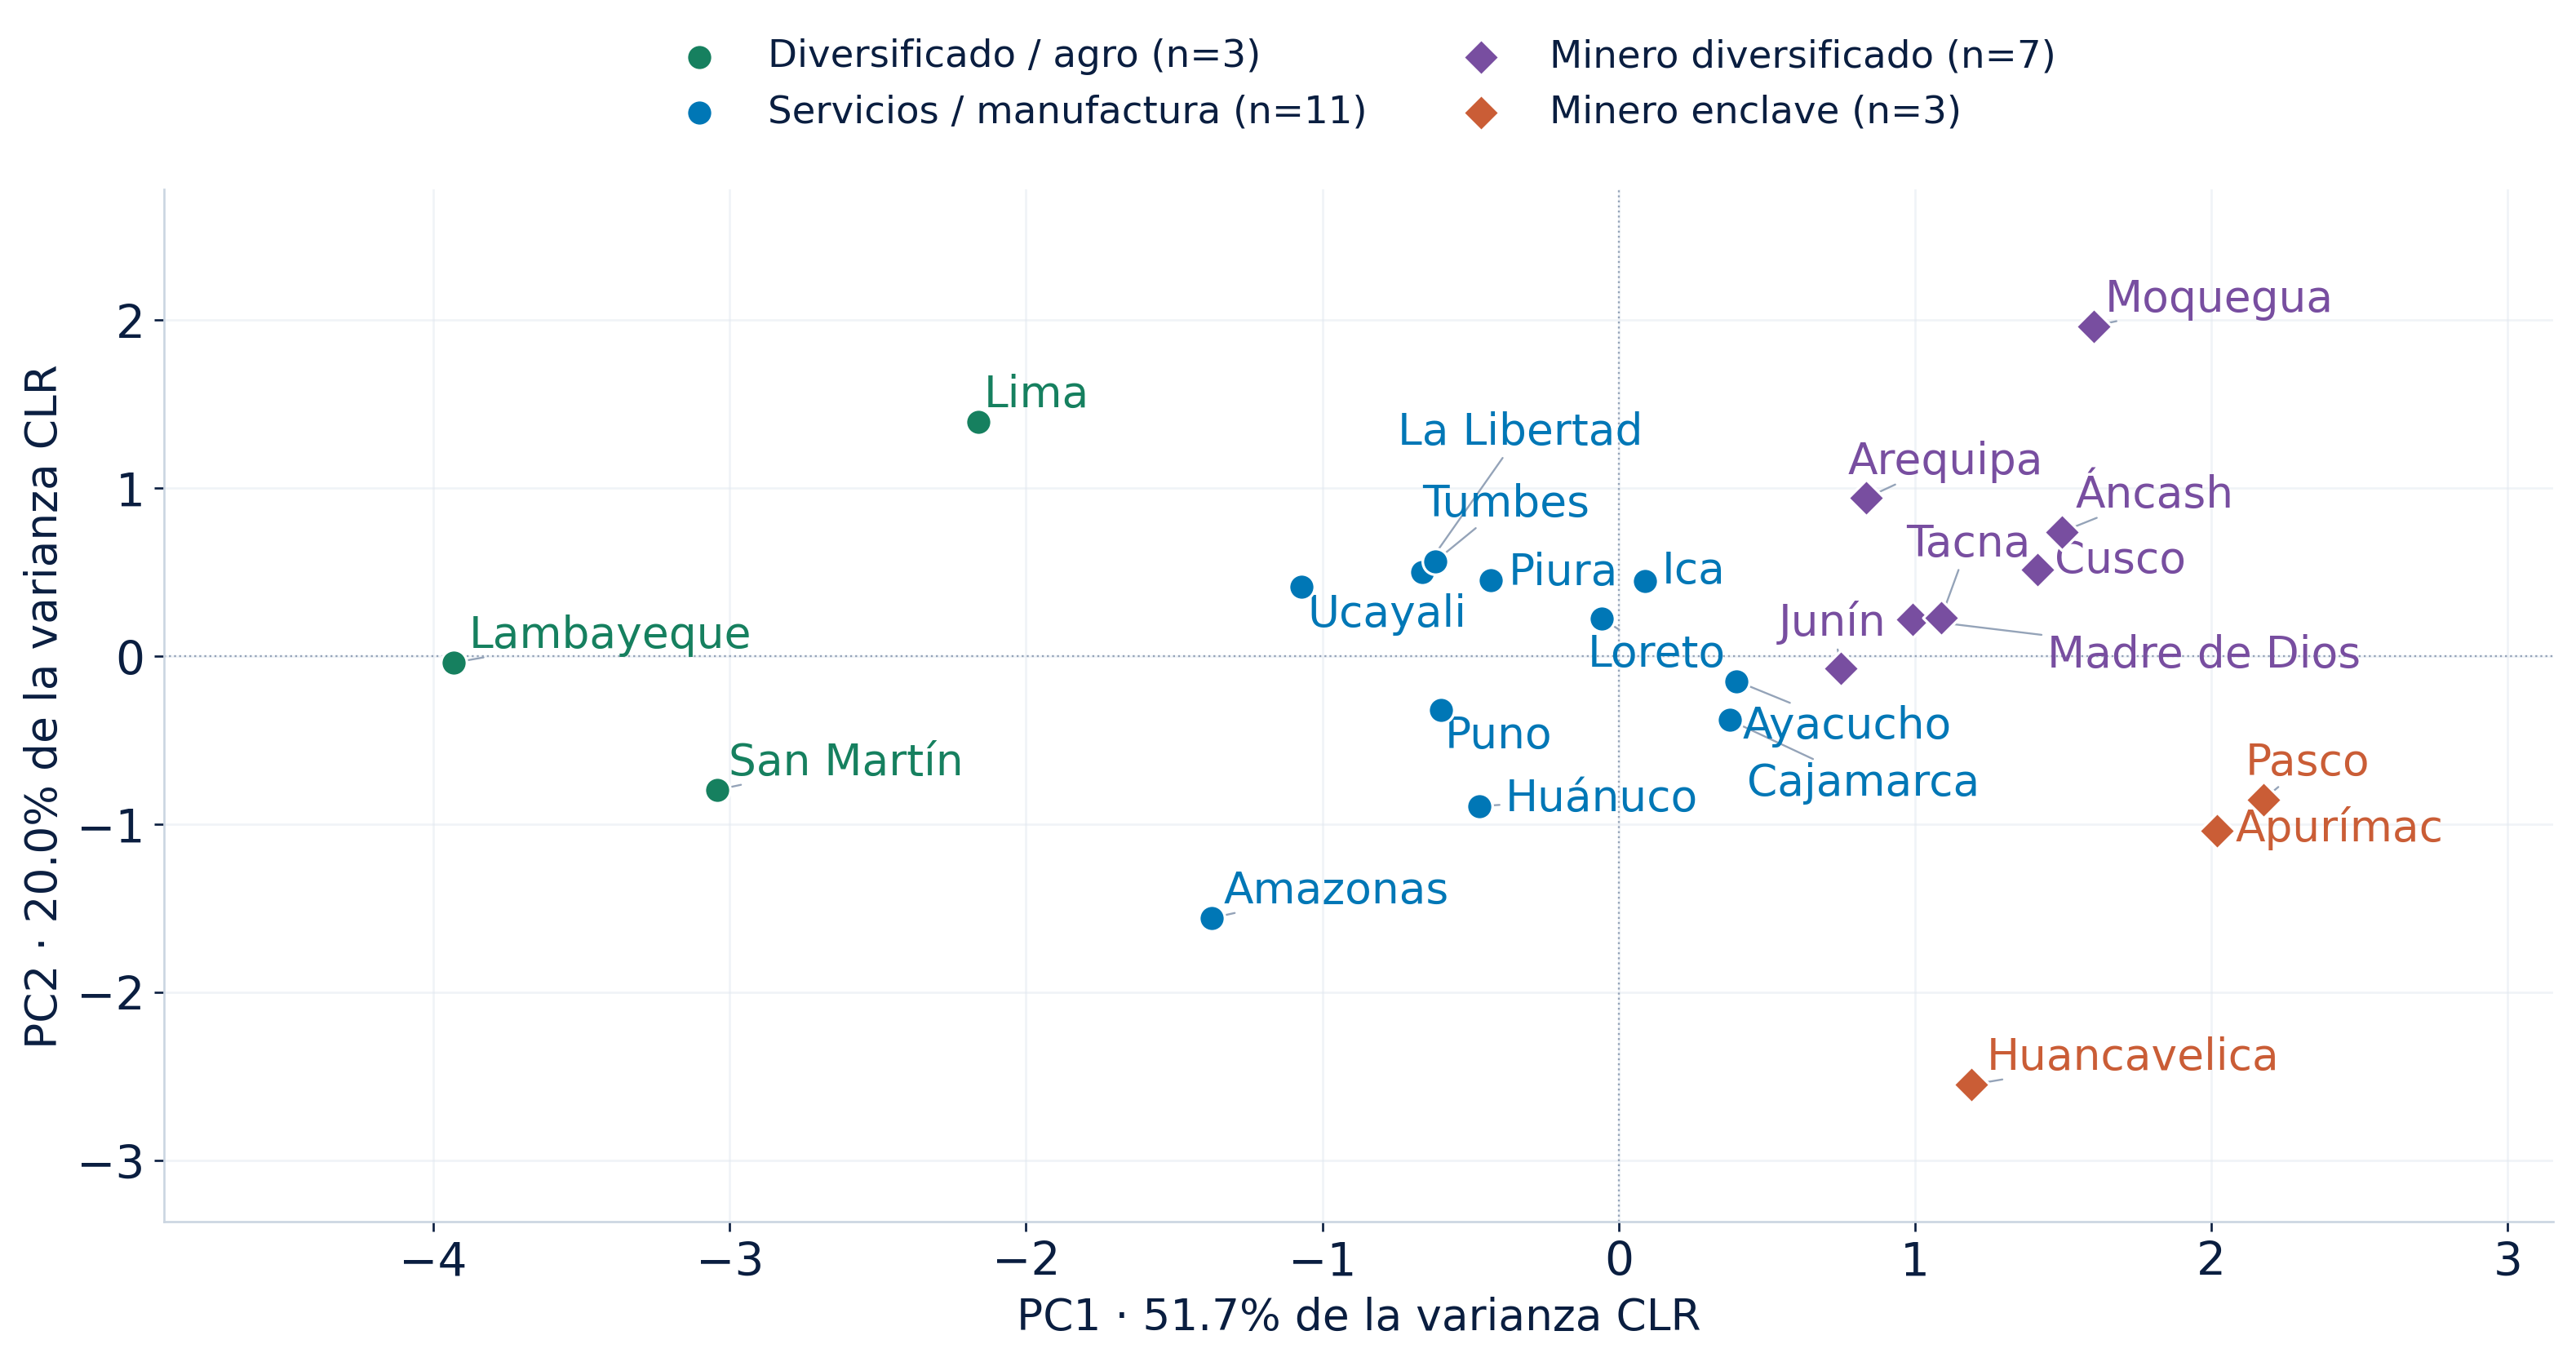

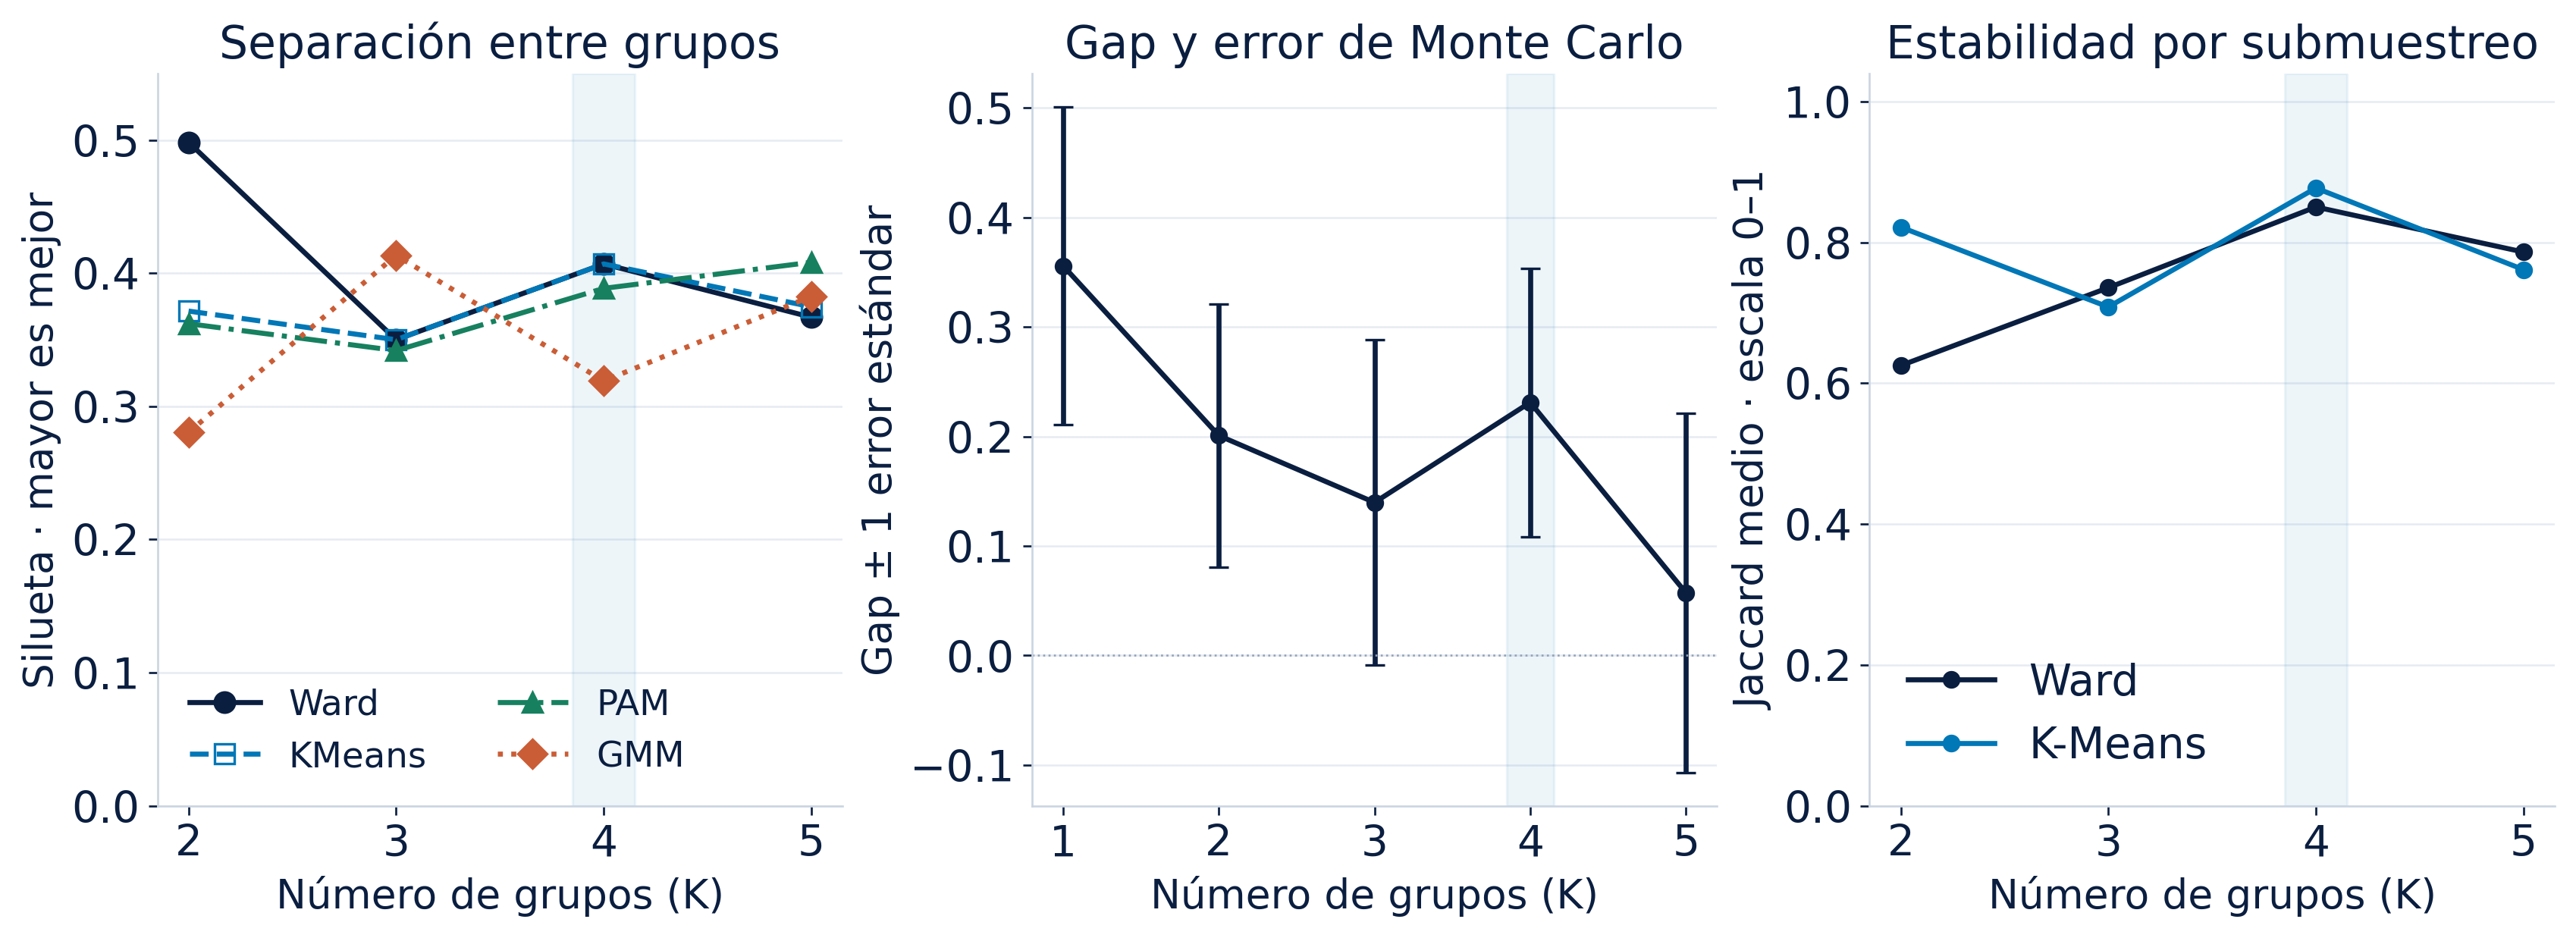

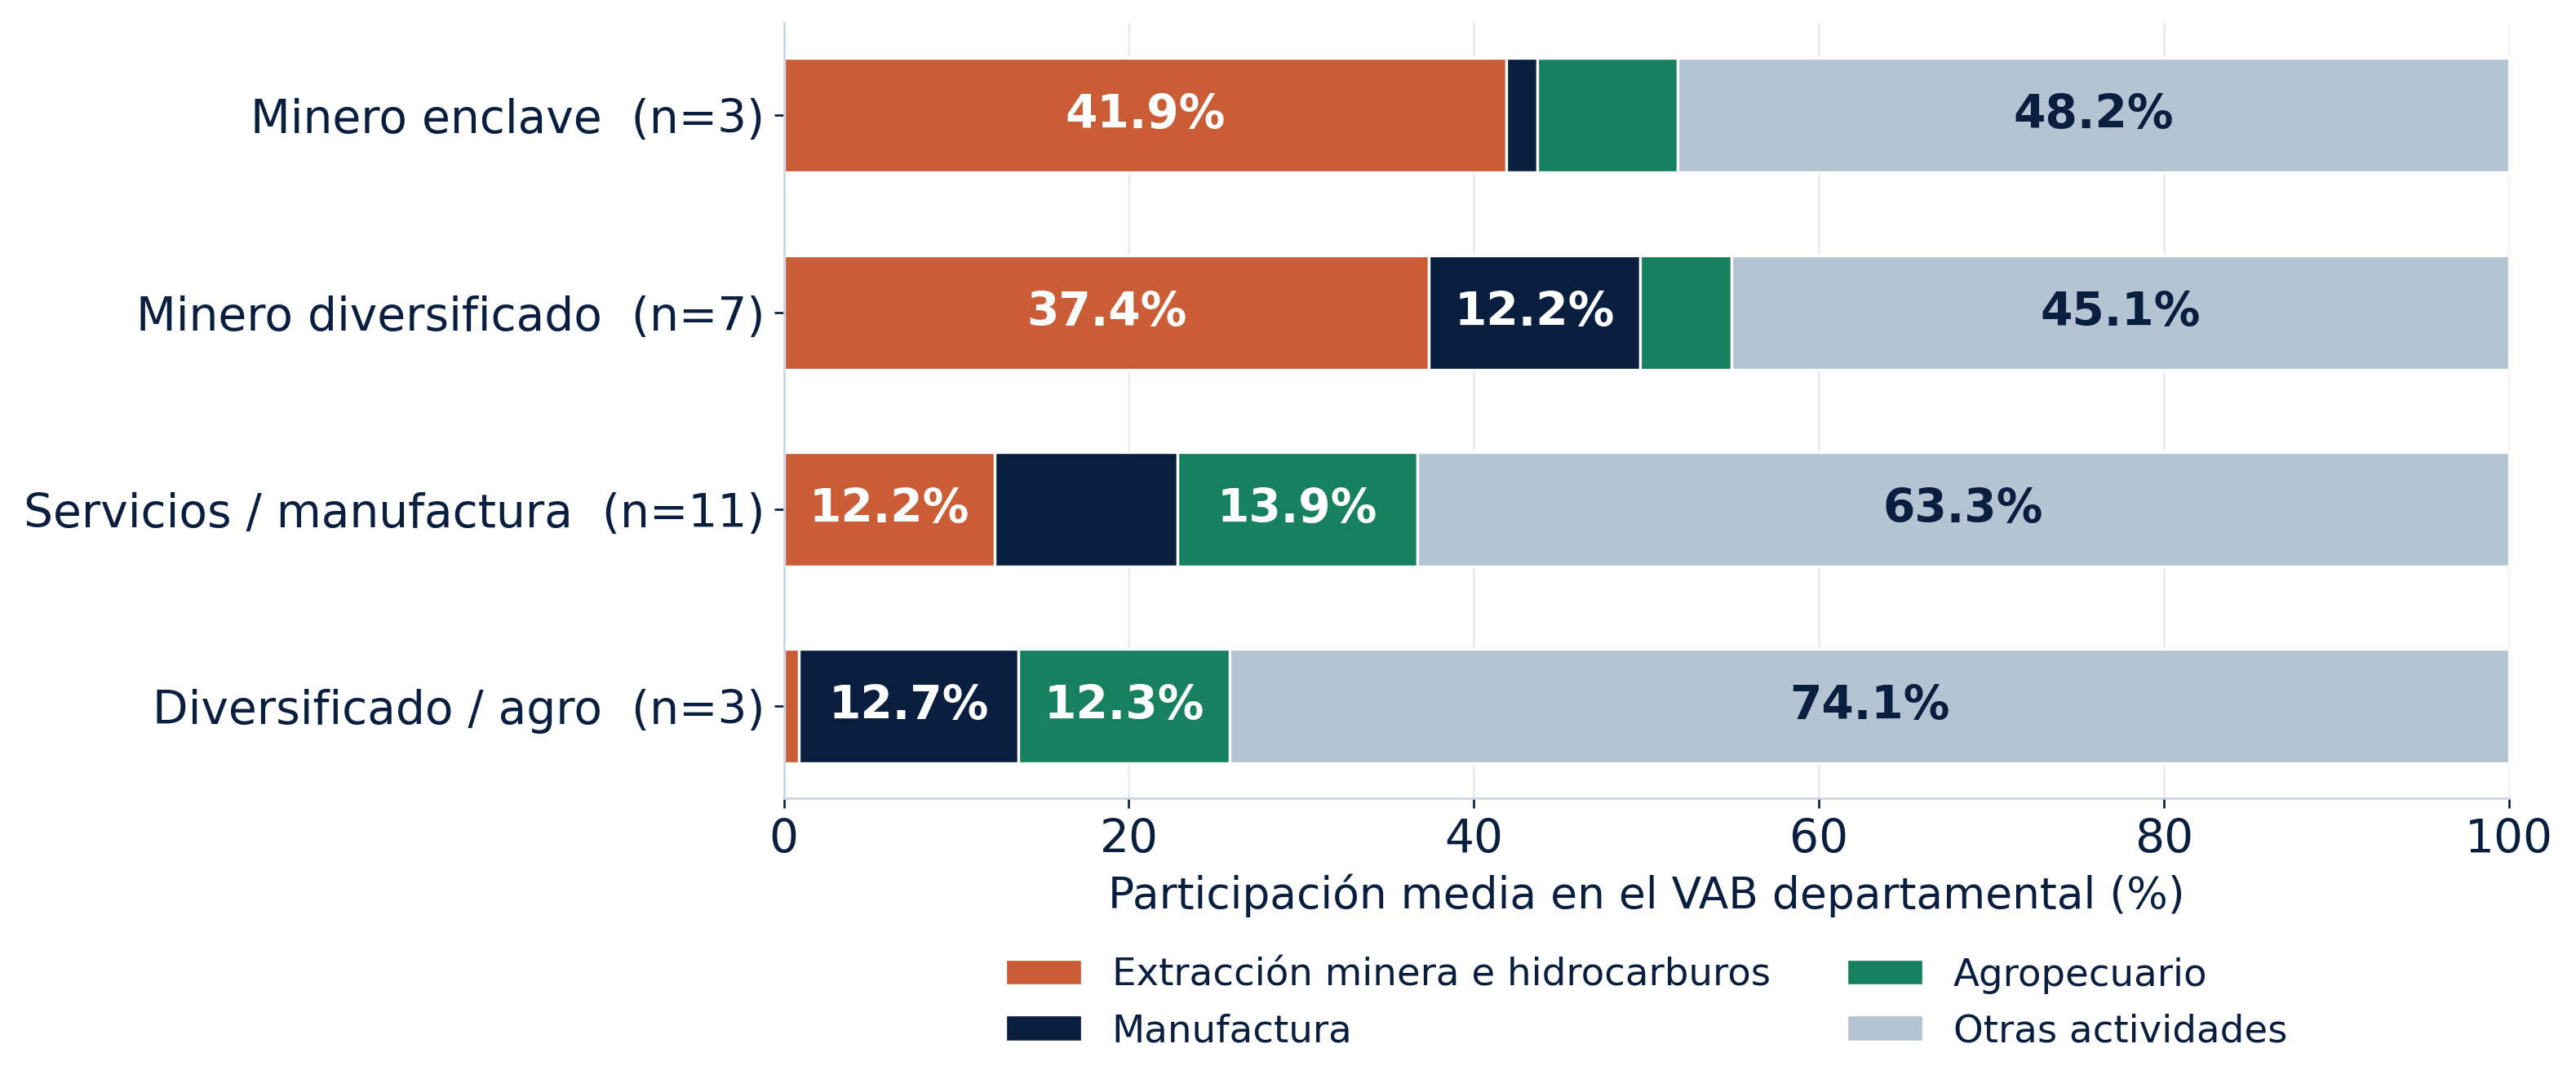

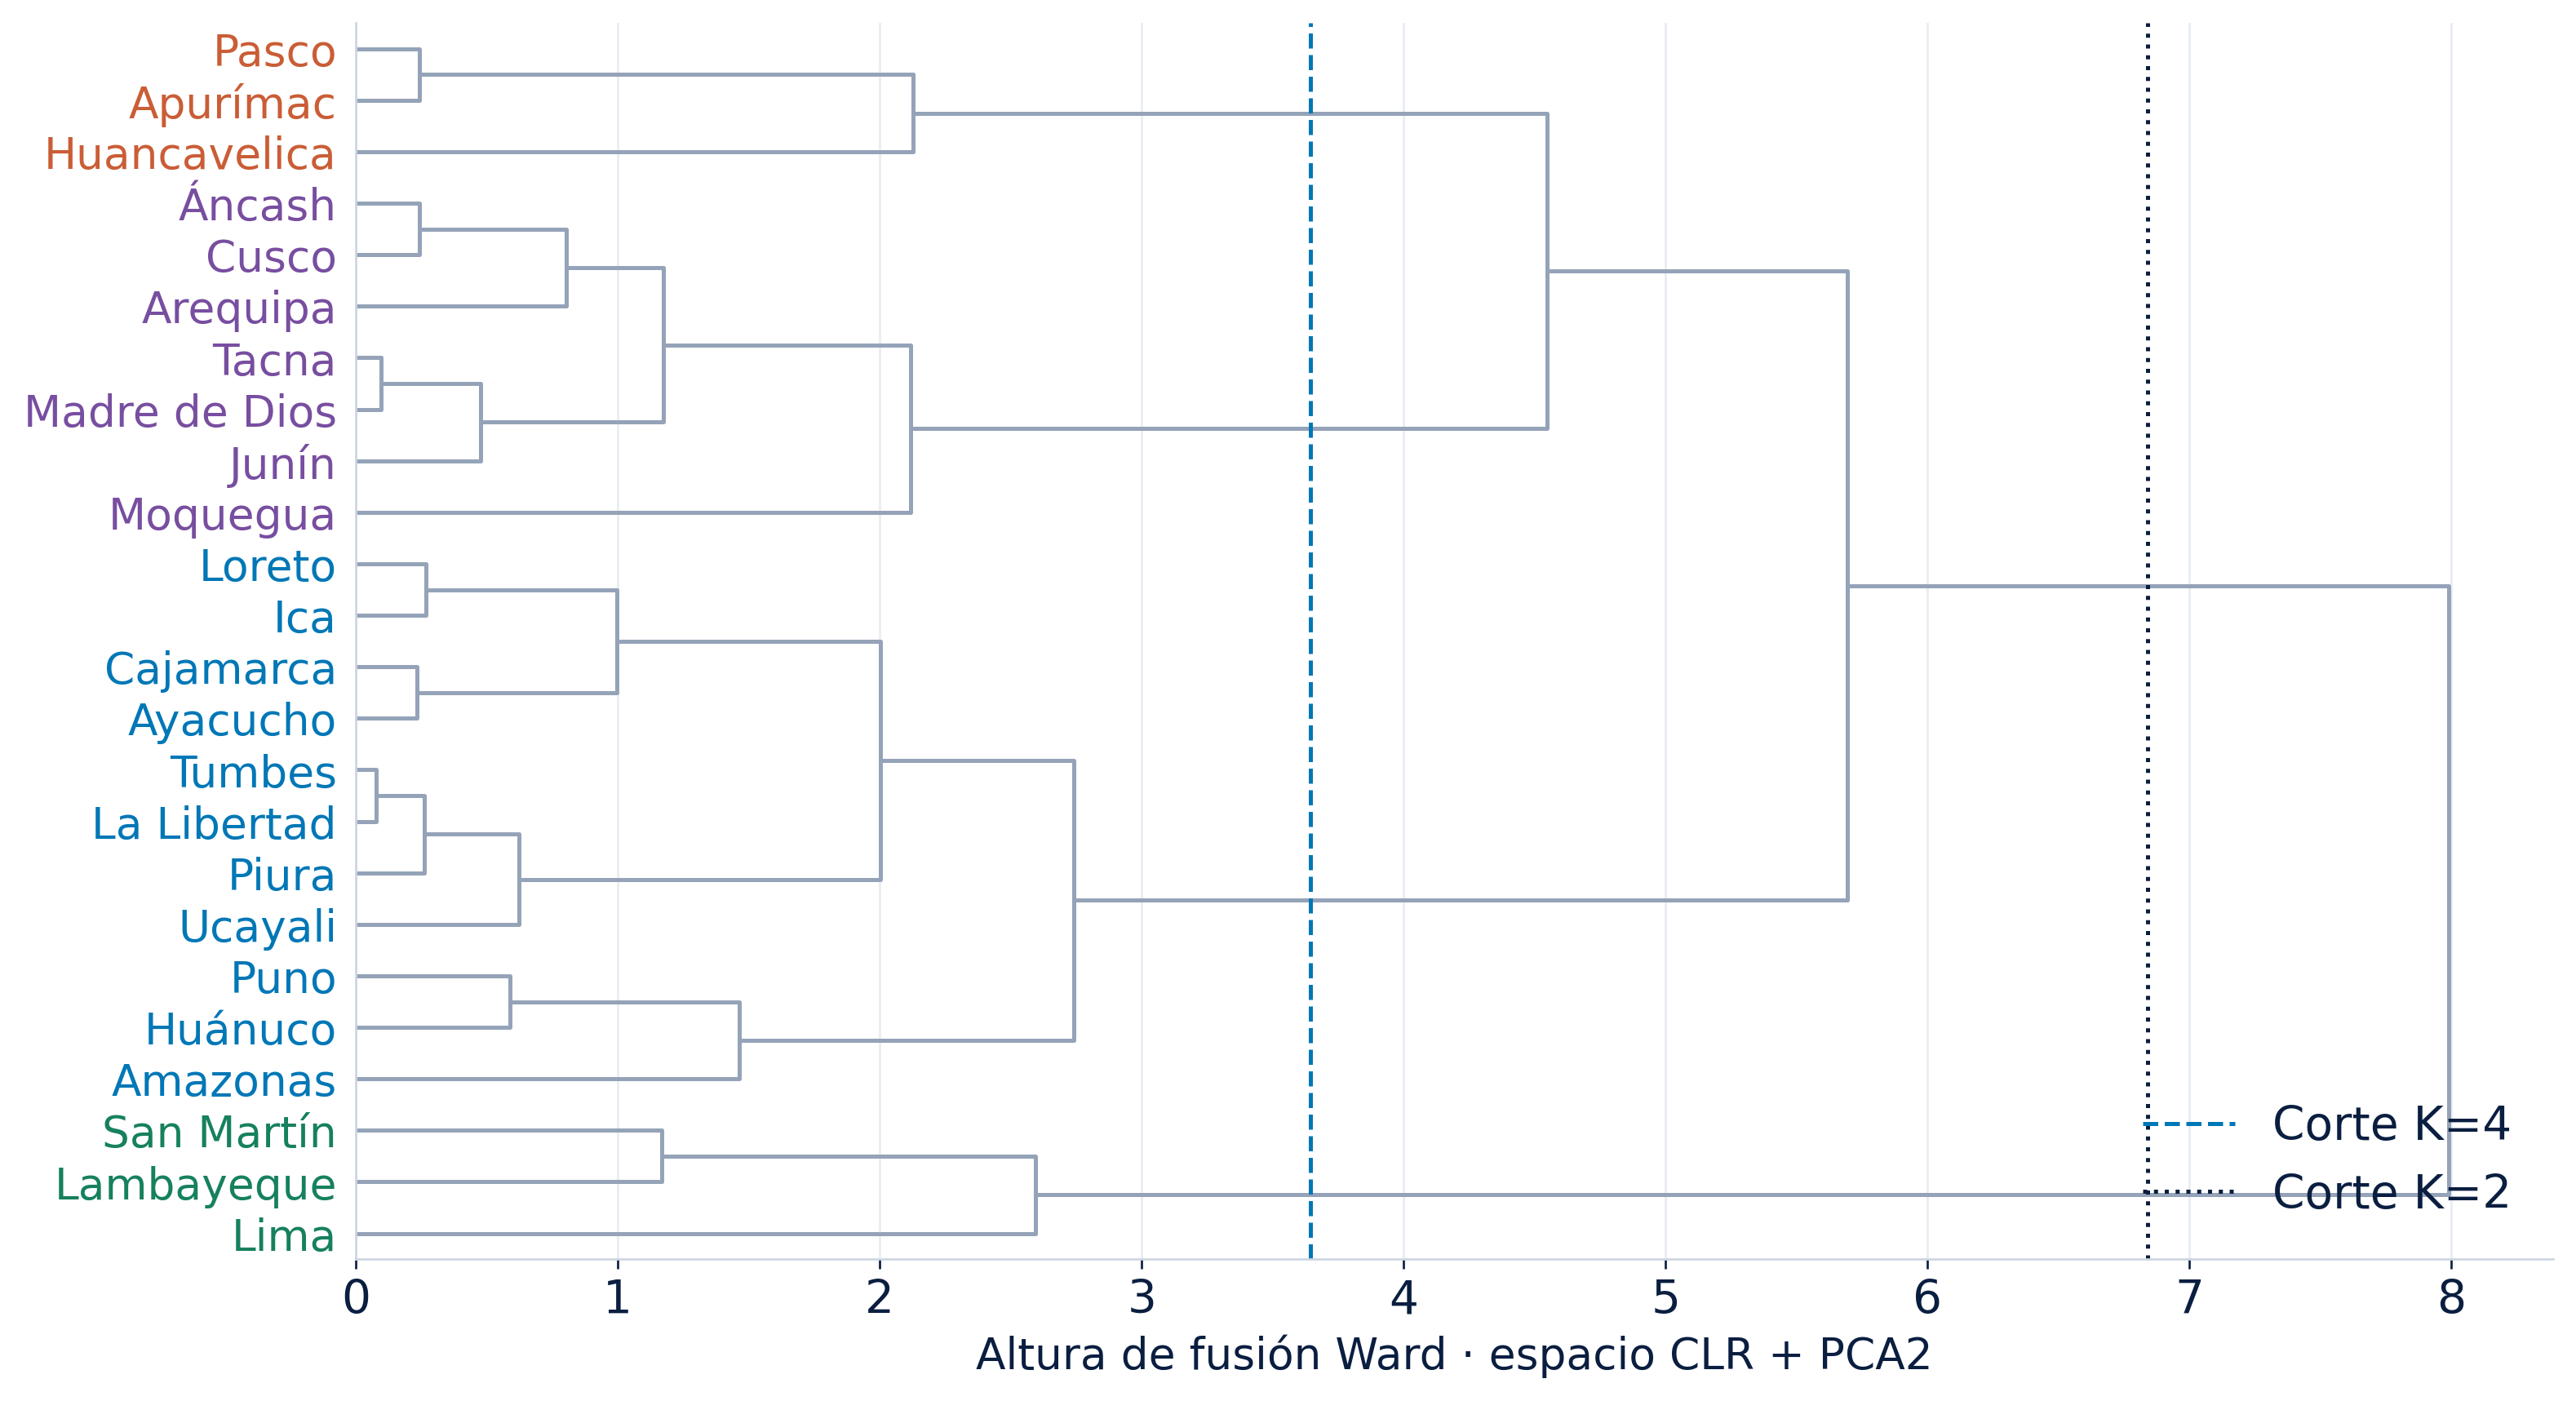

In [3]:
display(Image(filename=str(ROOT / "figures" / "fig1_pca_clusters.png"), width=1000))
display(Image(filename=str(ROOT / "figures" / "fig2_validacion_clustering.png"), width=1000))
display(Image(filename=str(ROOT / "figures" / "fig3_perfiles_sectoriales.png"), width=1000))
display(Image(filename=str(ROOT / "figures" / "fig3b_jerarquia_ward.png"), width=1000))